# $\log3$: historical CMF construction

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from cmfs import (
    RhinLog3CMF, huttner_logs, huttner_logs_seeds,
    rhin_log3_seeds, salikhov_log3, salikhov_log3_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}

target = lambda: arb(3).log()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Rhin (1987): polynomial insertions and an integer staircase

[Zudilin (2004), Section 3.4, equations (23)–(24)](https://arxiv.org/pdf/math/0404523).

**CMF:** rank-8 moments with Rhin's six polynomial factors.
**Start:** $(0,0,0,0,0,0,1)$. **Path:** $(\lfloor\alpha_1N\rfloor,\ldots,\lfloor\alpha_6N\rfloor,N+1)$,
where $\alpha=(.704324,.552418,.447582,.109072,.038934,.054368)$.
**Readout:** $(PW)_0/(QW)_0$. N is the source index; the walk applies the floors exactly.

In [5]:
cmf = RhinLog3CMF()
axes = cmf.axes
start = dict(zip(axes, [0] * 6 + [1]))
slopes = (704324, 552418, 447582, 109072, 38934, 54368)
trajectory = dict(zip(axes, [sp.Rational(a, 1000000) for a in slopes] + [sp.S.One]))
P, Q = rhin_log3_seeds()
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rhin (1987)'] = (DEPTHS, deltas)
accuracy['Rhin (1987)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.135412743869


## 2. Huttner (2003): $\log 3$ from the simultaneous construction

[Corollary 3.1(4), pp. 146–147](https://www.jstage.jst.go.jp/article/kyushujm/57/1/57_1_129/_pdf).

**CMF:** rank-3 moments of $(z-1)^u(z-2/3)^v(z-1/2)^w z^{-m}$.
**Start/direction:** $(2,2,2,3)$. Source index N uses N−1 steps.
**Readout:** $(PW)_0/(QW)_0$ from the source's simultaneous logarithmic coefficient rows.

In [7]:
u, v, w, m = sp.symbols('u v w m')
cmf = huttner_logs()
start = {u: 2, v: 2, w: 2, m: 3}
trajectory = {u: 2, v: 2, w: 2, m: 3}
P, Q = huttner_logs_seeds(3)
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Huttner (2003), simultaneous'] = (DEPTHS, deltas)
accuracy['Huttner (2003), simultaneous'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.103944270312


## 3. Salikhov (2007): symmetric integral construction

[Salikhov, *On the irrationality measure of ln 3*, Doklady Mathematics 76 (2007), 955–957](https://doi.org/10.1134/S1064562407060361).

**CMF:** rank-3 moments of $y^u(y-25)^v(y-49)^w(1225-y)^{-m}$.
**Start:** $(-1/2,0,0,1)$. **Direction:** $(1,1,1,2)$. N is the source index.
**Readout:** $(PW)_0/(QW)_0$, combining the source's two logarithmic integrals.
The integral formula is reproduced in .

In [9]:
u, v, w, m = sp.symbols('u v w m')
cmf = salikhov_log3()
start = {u: -sp.Rational(1, 2), v: 0, w: 0, m: 1}
trajectory = {u: 1, v: 1, w: 1, m: 2}
P, Q = salikhov_log3_seeds()
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Salikhov (2007)'] = (DEPTHS, deltas)
accuracy['Salikhov (2007)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.245250240537


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

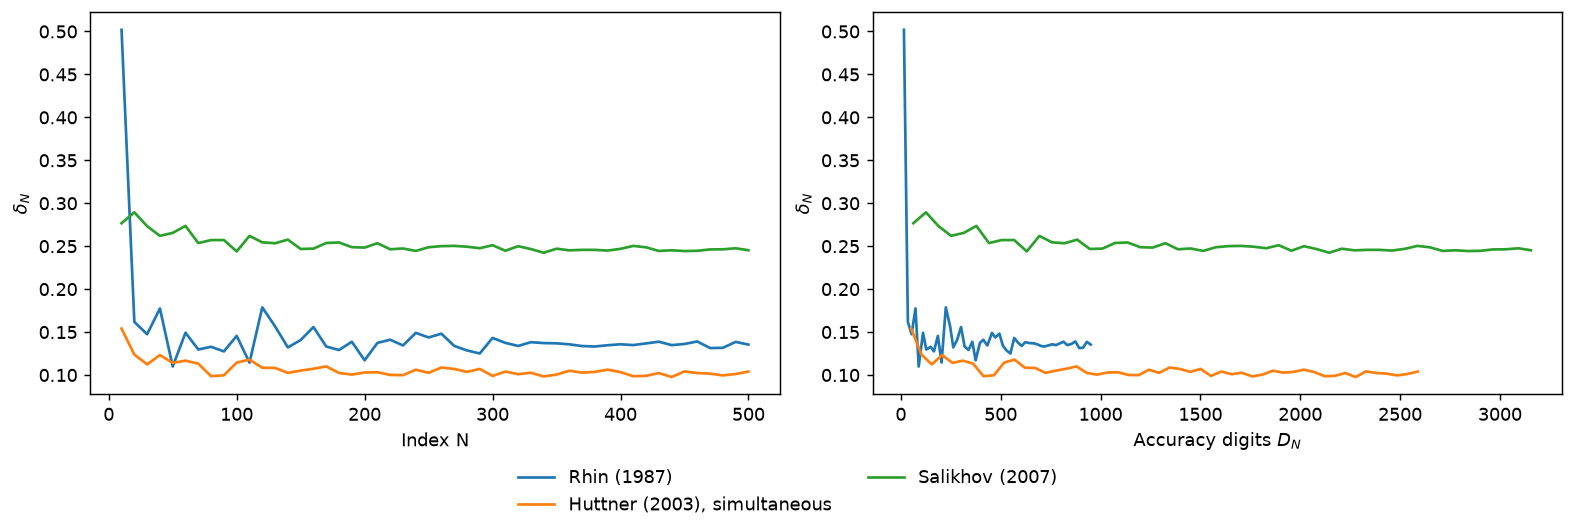

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Rhin (1987)': '$8.616$',
    'Huttner (2003), simultaneous': '$11.1017577\\ldots$',
    'Salikhov (2007)': '$5.125$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Rhin (1987) | $8.616$ | 0.135412743869 (N = 500) |
| Huttner (2003), simultaneous | $11.1017577\ldots$ | 0.103944270312 (N = 500) |
| Salikhov (2007) | $5.125$ | 0.245250240537 (N = 500) |